In [1]:
import scanpy as sc
import numpy as np
import scprep
from anndata import AnnData
import phate
from phate.cluster import kmeans
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

In [2]:
import sys
sys.path.append('..')
from dhg import Hypergraph
from hypgs.models.hsn_pyg import HSN
from hypgs.utils.data import HGDataset
from torch_geometric.loader import DataLoader
from torch_geometric.data import Dataset
import pytorch_lightning as pl
from pytorch_lightning.callbacks import EarlyStopping
from torch.utils.data import random_split
from pytorch_lightning.loggers import TensorBoardLogger
from hypgs import DATA_DIR
import anndata
import os
import torch
import numpy as np
import phate
from sklearn.neighbors import NearestNeighbors
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import euclidean_distances
import scanpy as sc
from sklearn.neighbors import kneighbors_graph
import random 
from torch_geometric.utils.convert import from_networkx
from importlib import reload
from hypgs.models.hsn_pyg import HyperScatteringModule
from torch_geometric.utils.convert import from_networkx
from einops import rearrange
from scipy.spatial import ConvexHull
from hypgs.utils.plot import plot_wavelets, get_hyperedge_pos_df, compute_enlarged_hulls, plot_hulls
from hypgs.utils.hypergraph_utils import get_cliques_planar
from scipy.spatial import Voronoi, voronoi_plot_2d
from hypgs.utils.graph_build import calcualte_voronoi_from_coords, build_graph_from_cell_coords, build_graph_from_voronoi_polygons, build_voronoi_polygon_to_cell_mapping, plot_voronoi_polygons, plot_graph, assign_attributes
from hypgs.utils.plot import get_wv_plots
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [3]:
adata_subset = sc.read_h5ad("merfish_H20.33.001.CX28.MTG.02.007.1.02.02.h5ad", backed='r')

In [4]:
coordinates = adata_subset.obsm['X_selected_cell_spatial_tiled']
coordinates = coordinates - coordinates.min(axis=0)
xmax, ymax = coordinates.max(axis=0)
voronoi_polygons = calcualte_voronoi_from_coords(coordinates[:, 0], coordinates[:, 1])
cell_data = pd.DataFrame(np.c_[adata_subset.obs.index, coordinates], columns=['CELL_ID', 'X', 'Y'])
G, node_to_cell_mapping = build_graph_from_cell_coords(cell_data, voronoi_polygons)
G = assign_attributes(G, cell_data, node_to_cell_mapping)

/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/pyg/lib/python3.9/site-packages/torch_geometric/utils/convert.py:260: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at ../torch/csrc/utils/tensor_new.cpp:261.)
  data[key] = torch.tensor(value)


Converting to hypergraph data:   0%|          | 0/1 [00:00<?, ?it/s]

Converting to hypergraph data: 100%|██████████| 1/1 [00:06<00:00,  6.96s/it]

Converting to hypergraph data: 100%|██████████| 1/1 [00:06<00:00,  6.97s/it]

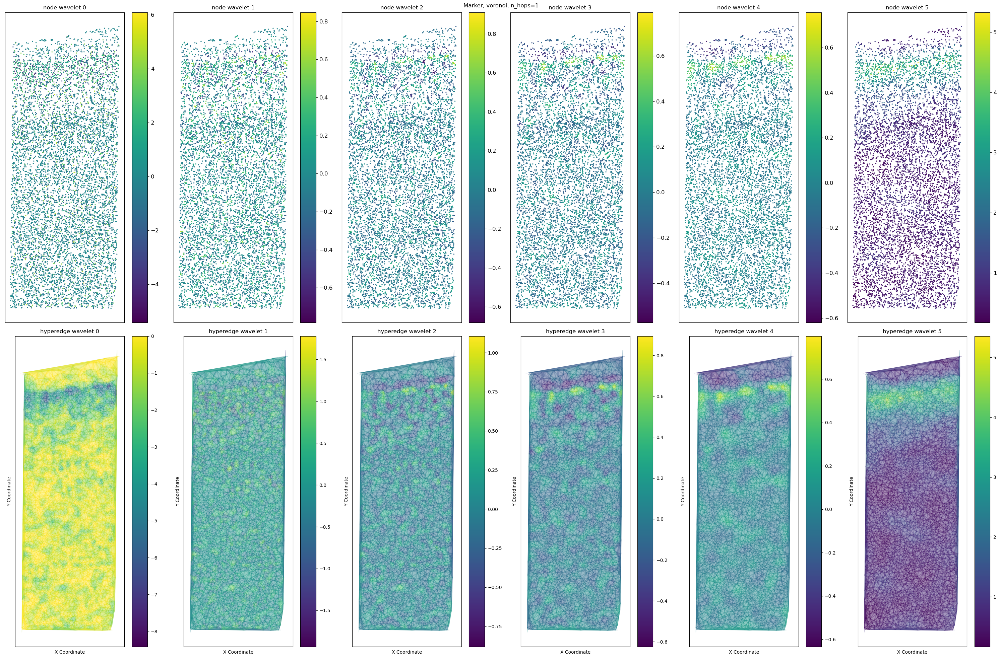

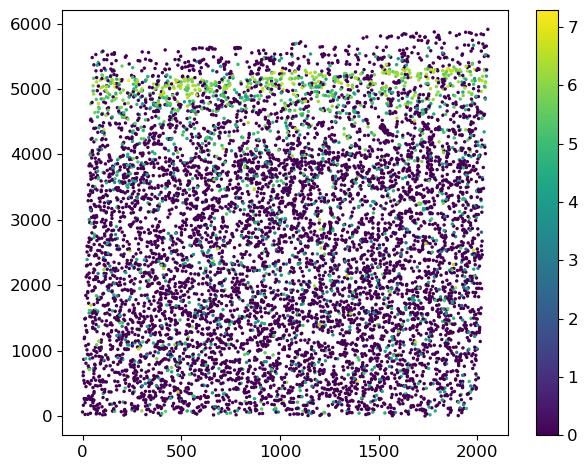

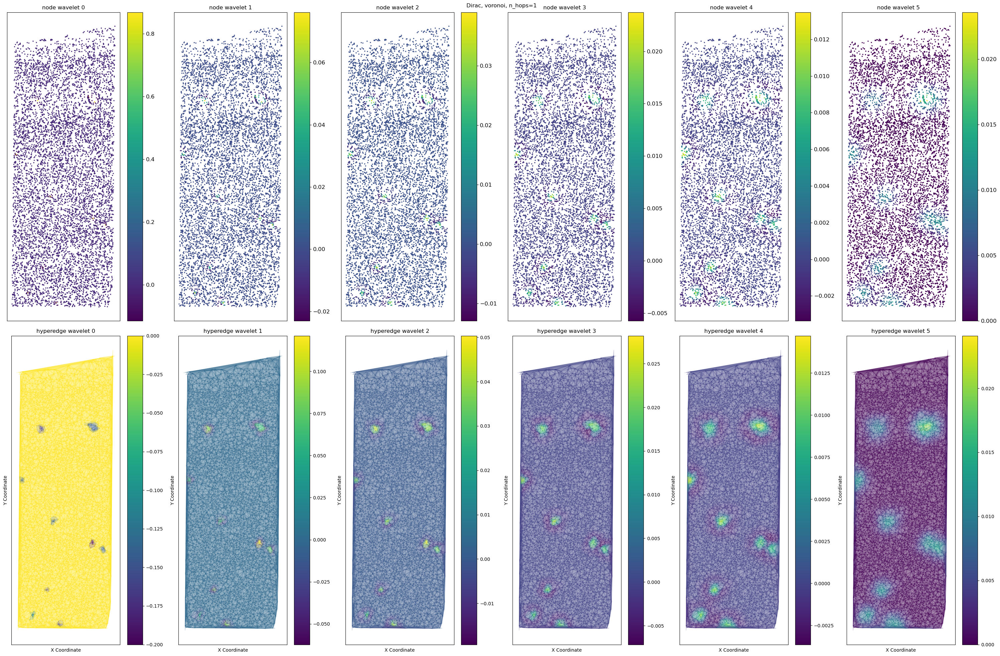

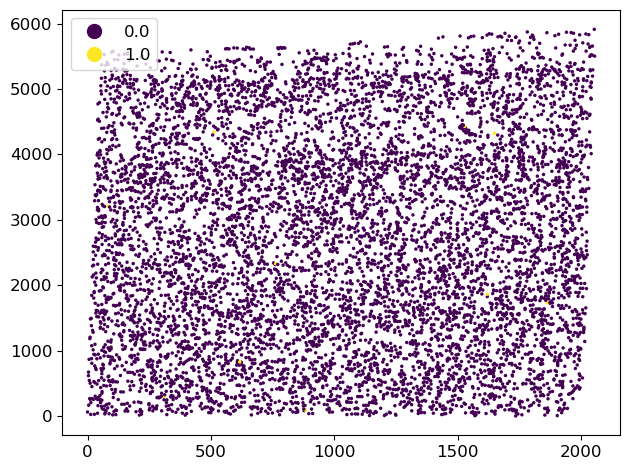

Converting to hypergraph data:   0%|          | 0/1 [00:00<?, ?it/s]

/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/pyg/lib/python3.9/site-packages/dhg/structure/hypergraphs/hypergraph.py:242: UserWarning: Sparse CSR tensor support is in beta state. If you miss a functionality in the sparse tensor support, please submit a feature request to https://github.com/pytorch/pytorch/issues. (Triggered internally at ../aten/src/ATen/SparseCsrTensorImpl.cpp:53.)
  A_k = torch.sparse.mm(A_k, A_1)


Converting to hypergraph data: 100%|██████████| 1/1 [00:11<00:00, 11.54s/it]

Converting to hypergraph data: 100%|██████████| 1/1 [00:11<00:00, 11.55s/it]

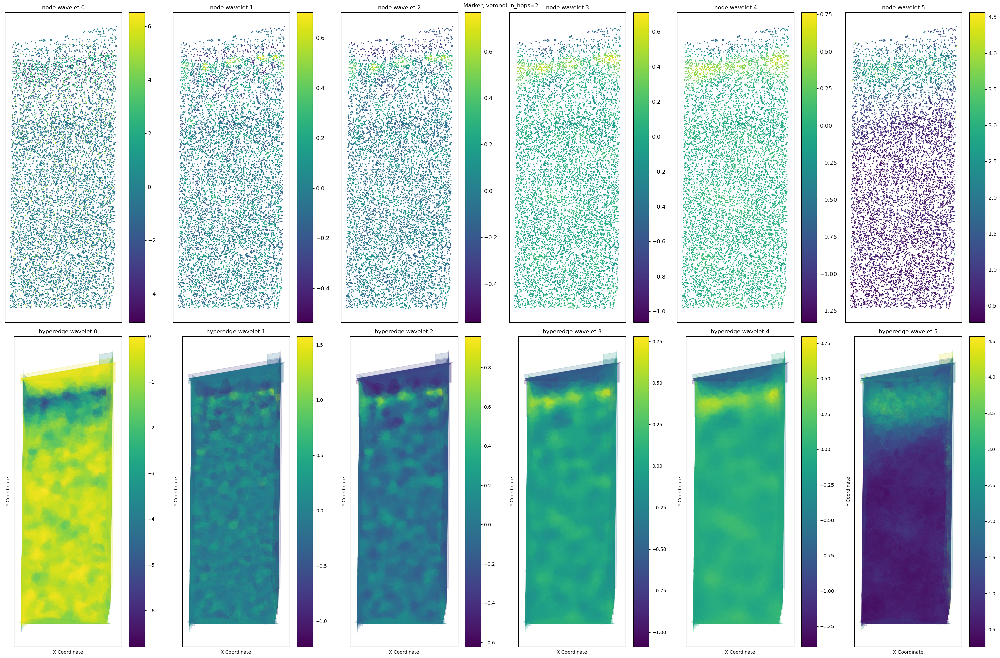

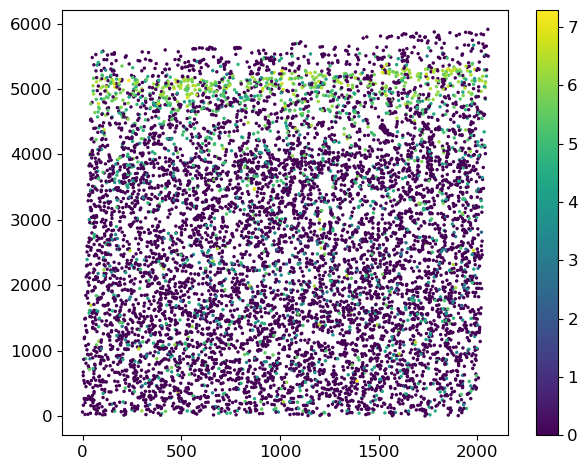

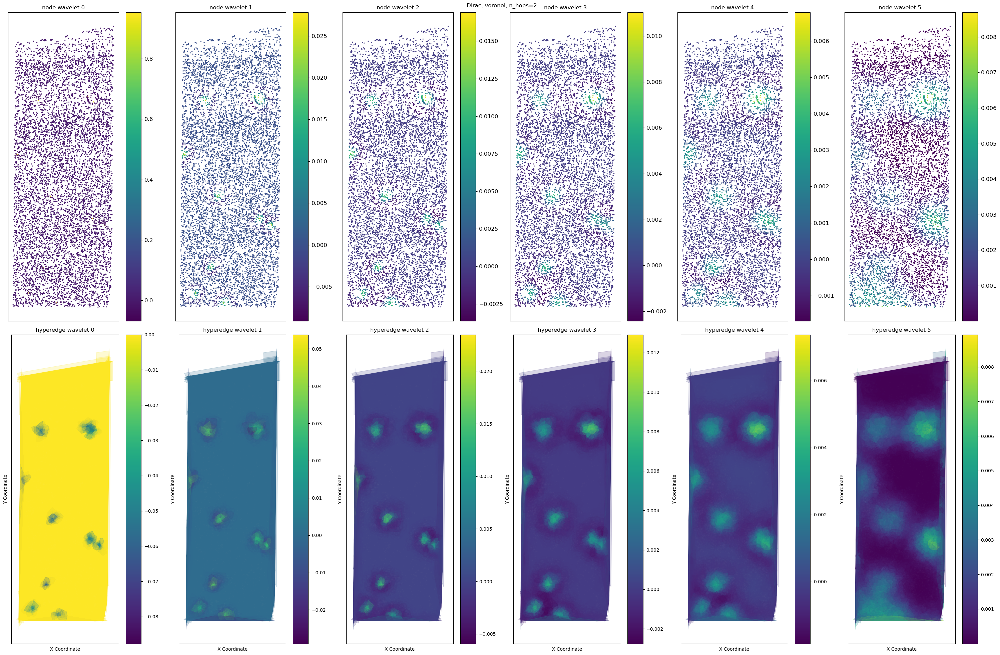

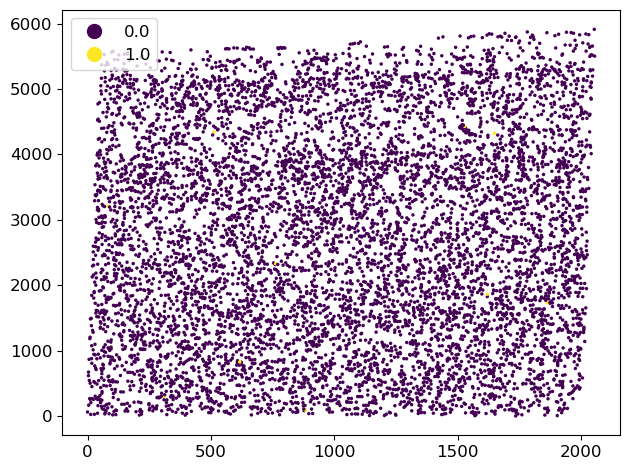

Converting to hypergraph data:   0%|          | 0/1 [00:00<?, ?it/s]

Converting to hypergraph data: 100%|██████████| 1/1 [00:21<00:00, 21.62s/it]

Converting to hypergraph data: 100%|██████████| 1/1 [00:21<00:00, 21.62s/it]

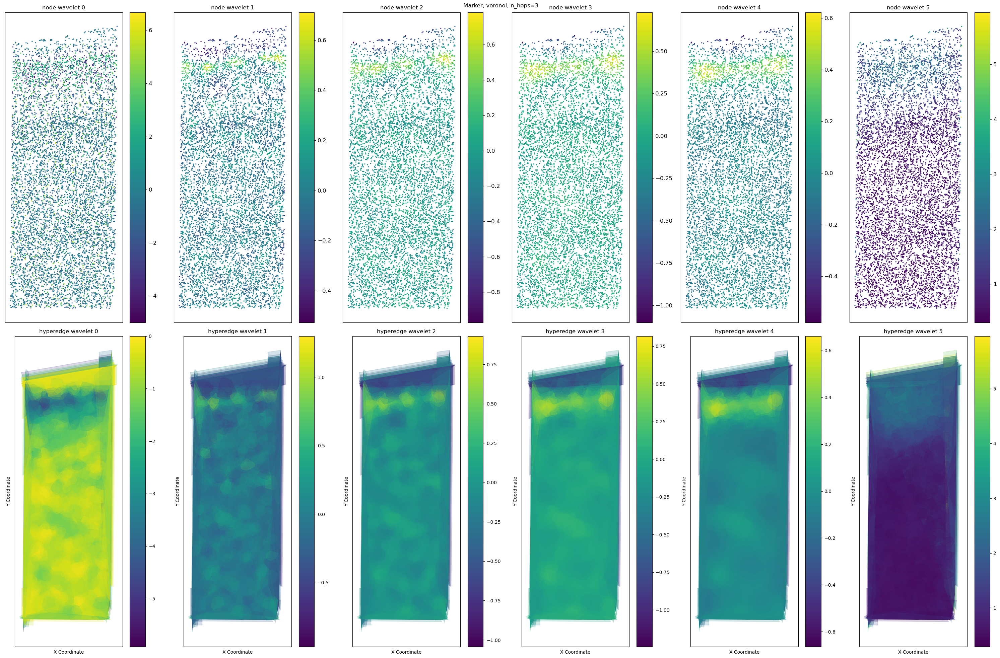

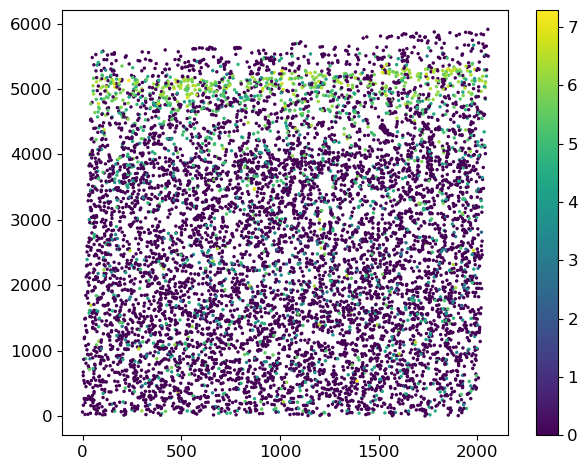

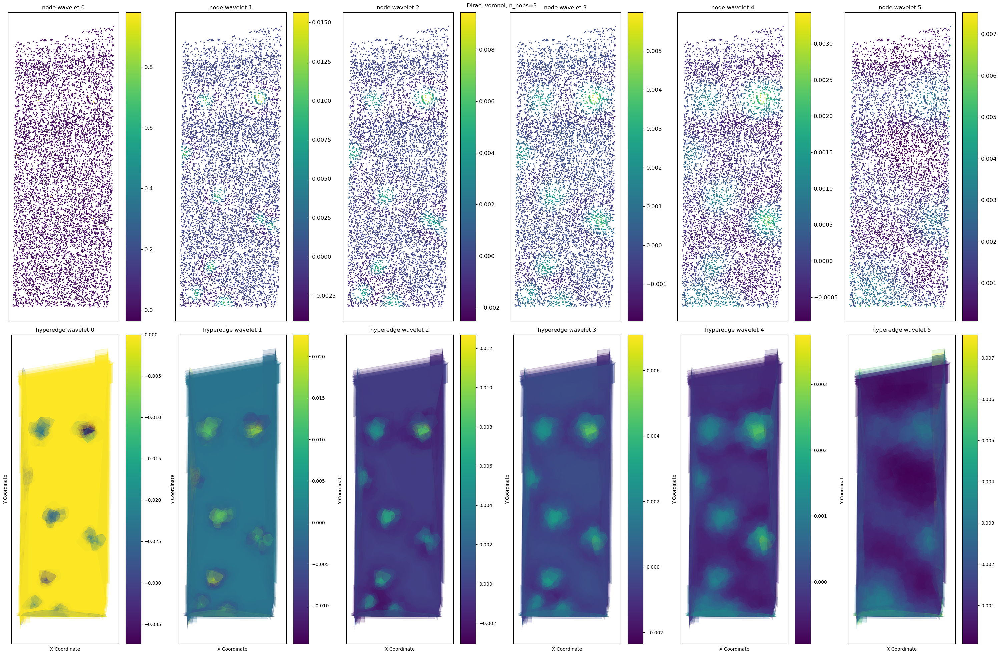

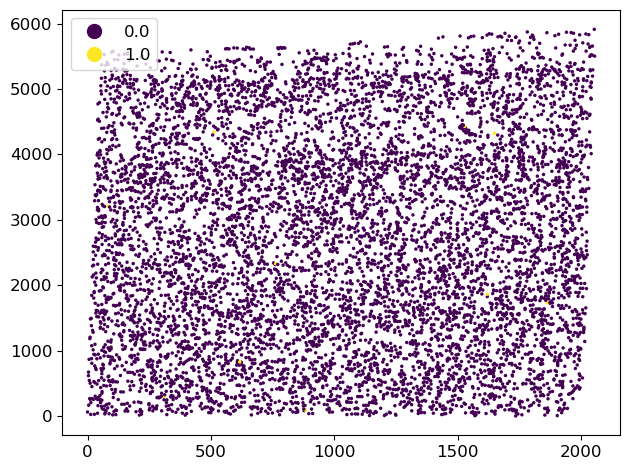

Converting to hypergraph data:   0%|          | 0/1 [00:00<?, ?it/s]

Converting to hypergraph data: 100%|██████████| 1/1 [00:43<00:00, 43.87s/it]

Converting to hypergraph data: 100%|██████████| 1/1 [00:43<00:00, 43.88s/it]

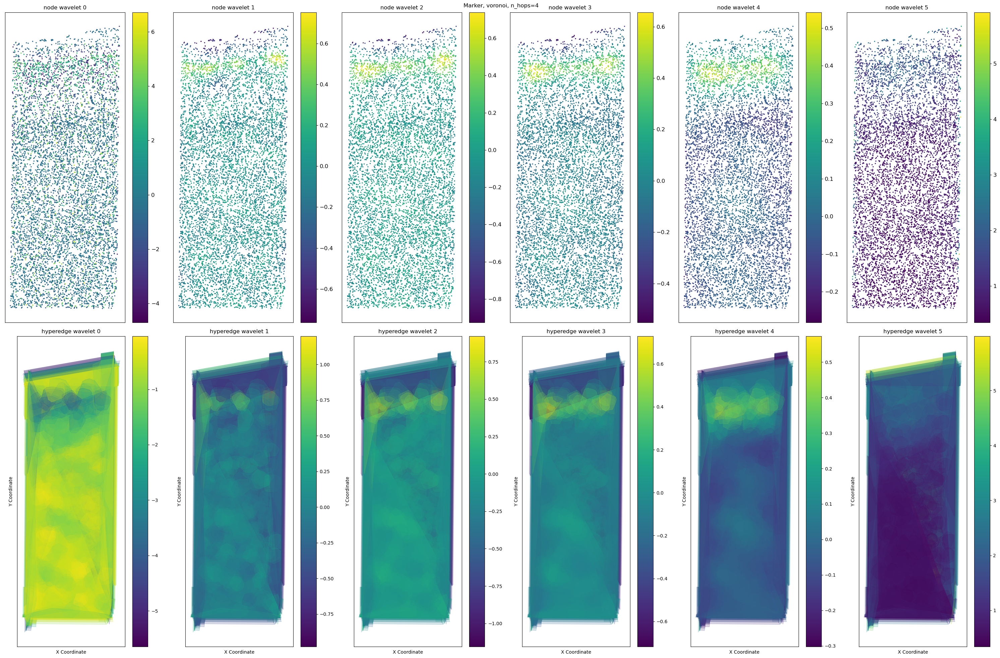

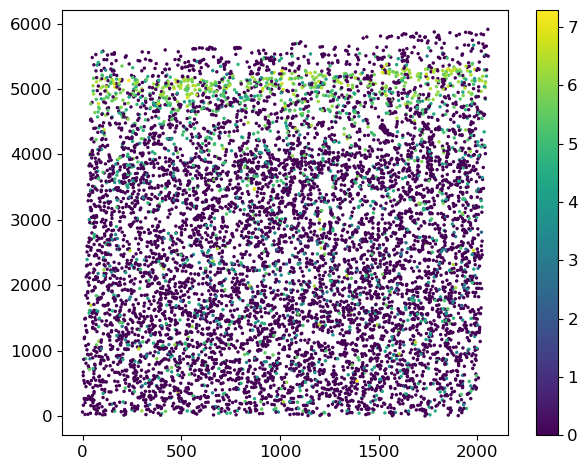

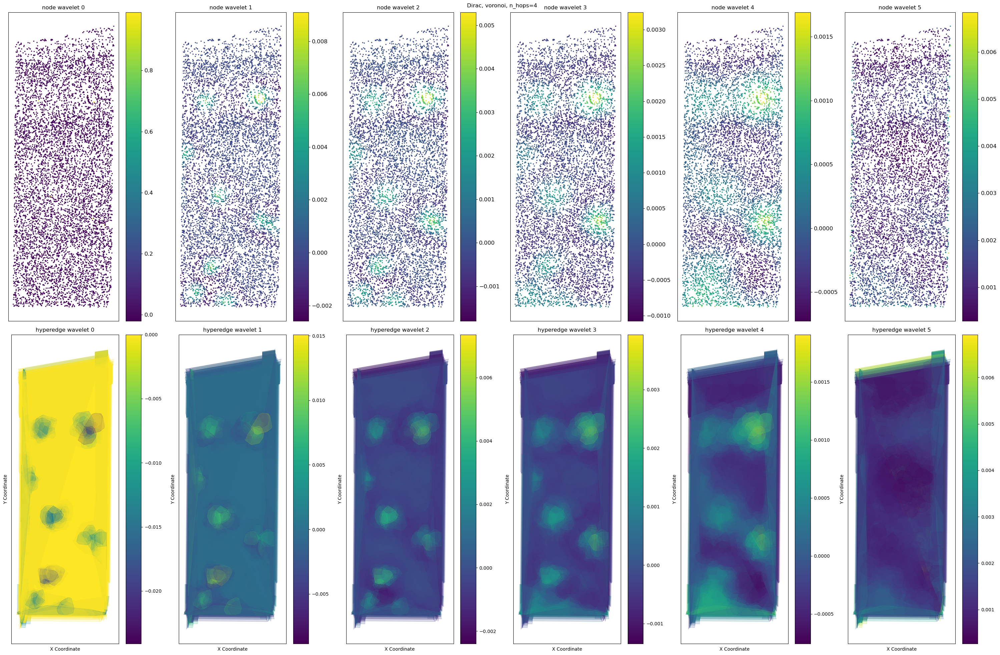

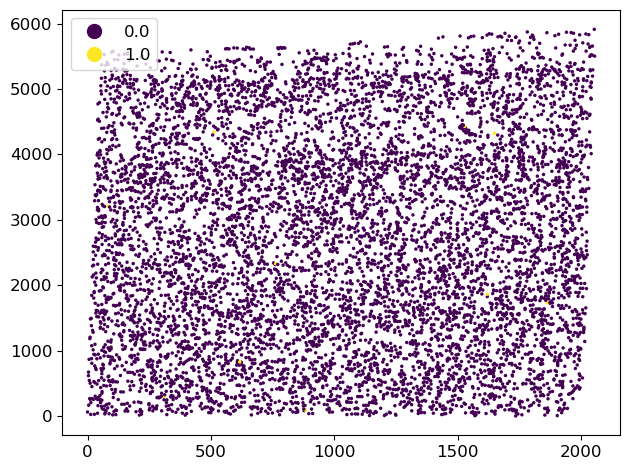

In [5]:
X_data = adata_subset[:,:].X.toarray()
for nhop in [1, 2, 3, 4]:
    get_wv_plots(G, X_data, coordinates, num_hops=nhop, graph_info='voronoi', device=device)